# Rewind the Sky — what did we know then?

Replay of the information available as **S250818k** unfolded (a low-significance LVK compact-binary
candidate, 2025-08-18 01:20:06 UTC, later linked to the optical transient AT 2025ulz).
The clock is set to a time *T*, and only what had *already* been published by *T* is shown.

**What this notebook does**

1. Rebuilds the event as a time-stamped log (LVK alert revisions from Astro-COLIBRI + GCN circulars).
2. Replays it at any *T* with a hard guarantee against hindsight leakage.
3. Shows the information vacuum, the localisation, and where/when it could be observed.
4. Replays three follow-up strategies with real tiling (tilepy) on the same strategy framework as the other case studies.
5. Offers a quiz mode for observer training.

Everything below runs **offline** from the cached data in `data/` (13 of 100 daily Astro-COLIBRI requests were used to build it).
**Read the "Known limitations" section before quoting any number.**

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import pandas as pd
from rewindsky.replay import load_log, state_at, t_after, parse_t, format_snapshot
from rewindsky import plots, plots_study as ps
from rewindsky.quiz import Quiz

pd.set_option("display.width", 200)
FIG = Path("figures/s250818k"); FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams["figure.dpi"] = 110
log = load_log("S250818k")
print(f"{log['event']}: t0 = {log['t0']} UTC, {log['n_rows']} information items "
      f"({sum(r['kind']=='gw_alert' for r in log['rows'])} LVK alert revisions, "
      f"{sum(r['kind']=='gcn_circular' for r in log['rows'])} GCN circulars)")

S250818k: t0 = 2025-08-18T01:20:06 UTC, 55 information items (5 LVK alert revisions, 50 GCN circulars)


## 1. When did each piece of information become available?

Each dot is one item at the moment it was published. Note the **8-hour silence** after the two preliminary
LVK alerts, and that the *Initial #3* / *Update #4* alerts only arrived ~2 days later.

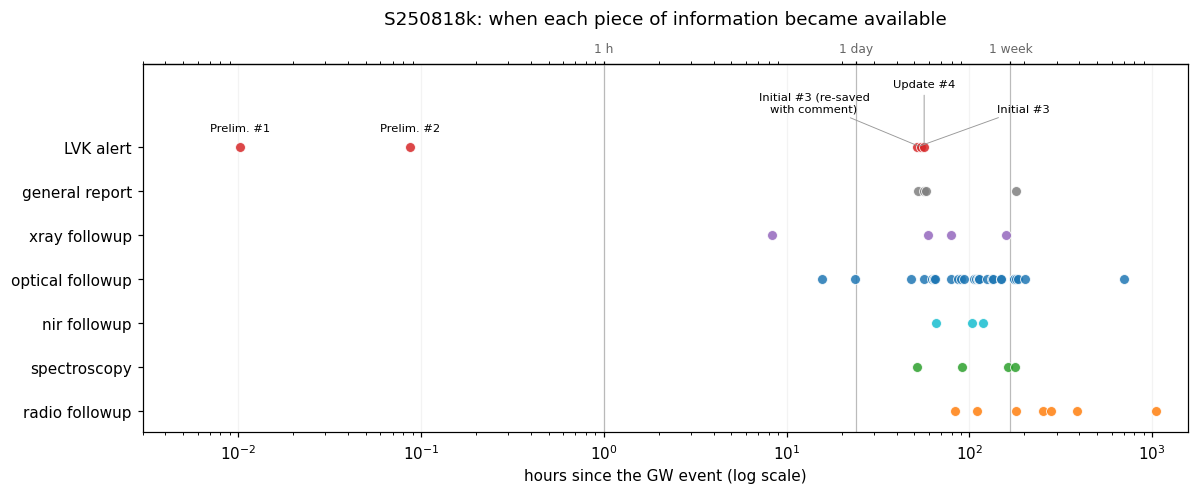

In [2]:
fig, ax = plt.subplots(figsize=(11, 4.6)); plots.timeline(log, ax=ax); fig.tight_layout(); fig.savefig(FIG / "01_timeline.png", dpi=130); plt.show()

## 2. The replay engine: `state_at(log, T)`

`state_at` only reads rows with `t <= T`, then a second, independent check (`check_no_leak`) re-derives the
allowed rows from scratch and **raises** if anything later than *T* appears.
Snapshots at four moments:

In [3]:
for kw in (dict(minutes=1), dict(minutes=10), dict(hours=6), dict(hours=57)):
    print(format_snapshot(state_at(log, t_after(log, **kw)))); print()

=== S250818k @ 2025-08-18T01:21:06  (T0 + 0.02 h) ===
Latest LVK alert: Preliminary #1 (available 2025-08-18T01:20:43)
  localisation: 50%=215 deg2  90%=805 deg2  lobes(90%): (71,-47), (254,+48)
  peak-probability pixel (not the localisation!): RA=98.9 Dec=-59.1
  distance ~263 Mpc  FAR=2.15 per year
  class: Terrestrial=71% BNS=29% NSBH=0% BBH=0%;  P(has NS | astrophysical)=1.0
  comment: (none)
Alerts so far: 1 -> Preliminary #1
GCN circulars so far: 0  {}

=== S250818k @ 2025-08-18T01:30:06  (T0 + 0.17 h) ===
Latest LVK alert: Preliminary #2 (available 2025-08-18T01:25:20)
  localisation: 50%=205 deg2  90%=786 deg2  lobes(90%): (72,-48), (253,+48)
  peak-probability pixel (not the localisation!): RA=242.4 Dec=+37.2
  distance ~259 Mpc  FAR=2.15 per year
  class: Terrestrial=71% BNS=29% NSBH=0% BBH=0%;  P(has NS | astrophysical)=1.0
  comment: (none)
Alerts so far: 2 -> Preliminary #1, Preliminary #2
GCN circulars so far: 0  {}

=== S250818k @ 2025-08-18T07:20:06  (T0 + 6.00 h) ===
L

### A leakage trap that the engine handles

LVK notice #3 was sent on 2025-08-20 04:52:51, but the Astro-COLIBRI record for it was re-saved at 07:47:32
with the comment *"sub-threshold trigger coincident with ZTF25abjmnps / AT 2025ulz"*. Replaying by the notice time
would show a comment nobody had yet. We use the revision's `last_modified` as the knowledge time:

In [4]:
for T in ("2025-08-20T06:00:00", "2025-08-20T08:00:00"):
    a = state_at(log, T)["latest_alert"]
    print(T, "|", a["label"], "| comment:", repr(a["comment"]))

2025-08-20T06:00:00 | Initial #3 | comment: ''
2025-08-20T08:00:00 | Initial #3 | comment: 'sub-threshold trigger coincident with ZTF25abjmnps / AT 2025ulz'


## 3. Localisation: the "jump" is not a jump

Between *Preliminary #1* and *#2* the single best-position pixel moves from Dec −59° to Dec +37°.
But both maps contain the **same two lobes** (south ≈ (72°, −48°), north ≈ (253°, +48°)) with almost identical
area (805 → 786 deg²). The peak pixel just flipped between lobes — typical for two-detector localisations.
Showing a single point would mislead; the contours do not.

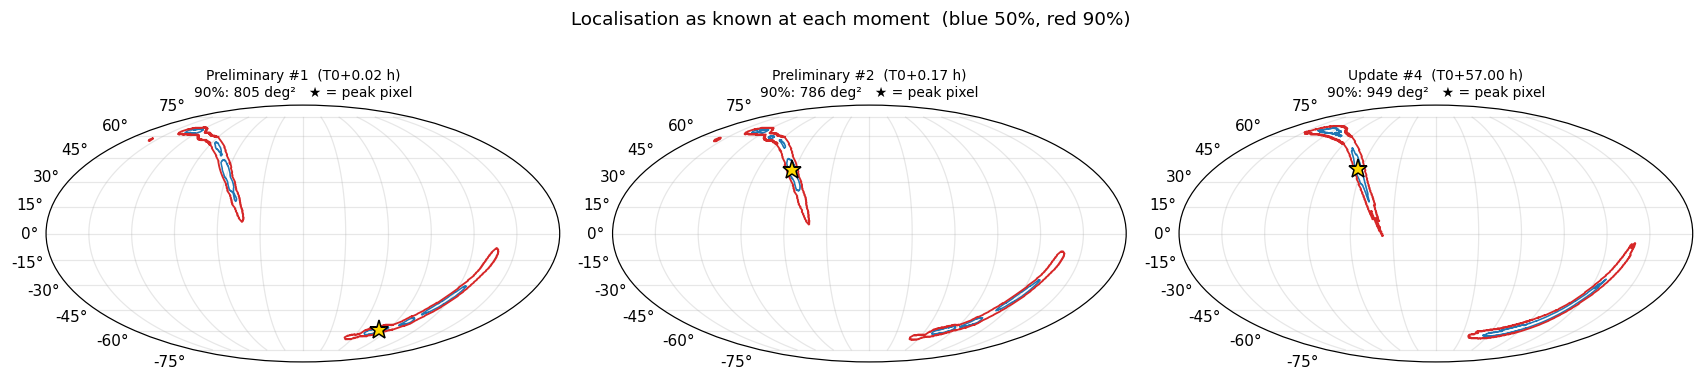

In [5]:
fig = plots.skymap_sequence(log, [0.02, 0.17, 57]); fig.savefig(FIG / "02_skymaps.png", dpi=110, bbox_inches="tight"); plt.show()

## 4. How much was known? How much could be observed?

The follow-up literature arrives only from ~8 h on and mostly after day 2 — the early decisions are made in
near-total information vacuum.

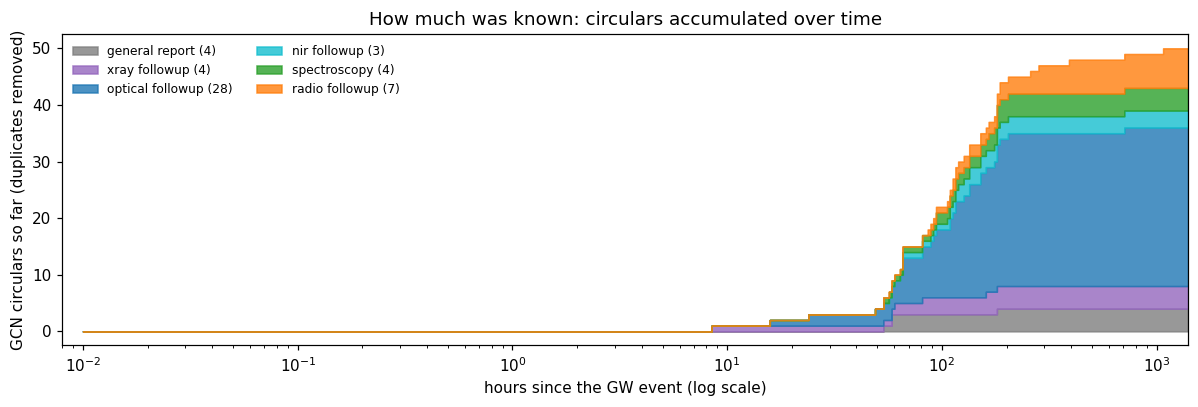

In [6]:
fig, ax = plt.subplots(figsize=(11, 3.8)); plots.knowledge_growth(log, ax=ax); fig.tight_layout(); fig.savefig(FIG / "03_growth.png", dpi=130); plt.show()

**Geometric visibility** at three sites for the two lobes (computed locally with astropy). The band is the altitude range
over the whole 90 % contour — the lobes are ~60° long arcs, so a single centre point would be misleading.
*This plot ignores the Moon and weather.*

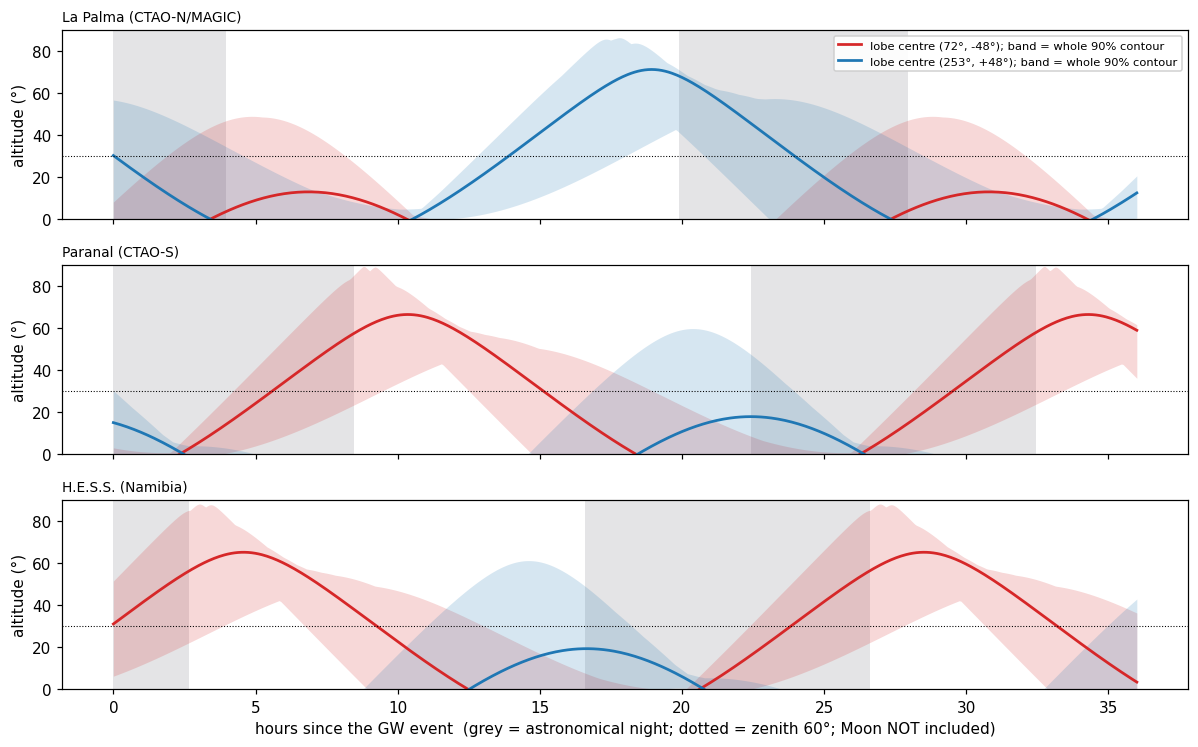

In [7]:
T = t_after(log, minutes=10)
lobes = state_at(log, T)["latest_alert"]["lobes_90"]
plots.visibility(log, lobes, hours=36, loops=plots.lobe_loops(log, T)); plt.gcf().tight_layout(); plt.gcf().savefig(FIG / "04_visibility.png", dpi=130); plt.show()

## 5. Three follow-up strategies, replayed

Each strategy decides **only with what was known at its decision time** (the knowledge times of the log above); tiles come from
[tilepy](https://pypi.org/project/tilepy/) (2D probability-greedy, circular field of view of **5° diameter**
(= tilepy `fov` radius 2.5°), 20-min tiles, zenith ≤ 60°, Sun < −18°, up to 2 nights) at two sites (La Palma, Paranal).

| | decision | information used |
|---|---|---|
| **A** act at once | T+1 min, re-plan at T+5 min | GraceDB `bayestar,0`, then `bayestar,1` |
| **B** wait for optical candidate | T+15.7 h (GCN 41414) | position of AT 2025ulz (single pointing) |
| **C** wait for LVK update | T+56.6 h (notice #4) | Bilby sky map |

Moon policy (baseline): observe if the Moon is down, **or** below 30° altitude (at any illumination), **or** higher up but ≤ 30 % illuminated
(tilepy grey-time semantics; the first night has a 29 %-lit waning Moon, the night of C a 6 % one).

The strategies run on the generic strategy framework `rewindsky/study.py`, the same one as the other two case studies: when A re-plans,
the tile already running is kept **and passed to tilepy as already observed**, so the re-plan does not point at it again.
(The first version of this analysis did not pass it; its tiles are kept in `data/strategies/S250818k_v1/`, see the comparison below.)

The tiles are scored against three **hypotheses about where the source was** (evaluation only, never used for planning):

* **Hfinal** — the Bilby map, the best LVK localisation (the only truth of the first version);
* **Hearly** — the map known at T+5 min (shows how much the scoring depends on the choice of map);
* **Hcand** — AT 2025ulz *is* the counterpart (a point source at its position; later work found it to be a supernova).

In [8]:
from rewindsky import study, s250818k as E
E.ensure_candidate_truth()
res = study.run_study(E.EVENT, E.STRATEGIES, list(E.SENSITIVITY.values()))   # cached; ~1 min with 10 processes if not
frames = {n: study.summarise(res, su.tag(), E.STRATEGIES, E.TRUTHS, su, E.T0) for n, su in E.SENSITIVITY.items()}
summ = frames["baseline (2 sites, grey)"]
summ[["decision_h", "first_tile_h", "n_tiles", "cov_Hfinal", "t10_Hfinal_h", "t25_Hfinal_h", "cov_Hearly", "t10_Hcand_h"]]

,decision_h,first_tile_h,n_tiles,cov_Hfinal,t10_Hfinal_h,t25_Hfinal_h,cov_Hearly,t10_Hcand_h
strategy,,,,,,,,
A,0.01,0.01,42,0.6752,2.01,6.01,0.7897,20.52
B,15.69,19.86,2,0.0279,NaN,NaN,0.0300,19.86
C,56.62,67.82,40,0.7098,68.48,70.48,0.7670,68.48


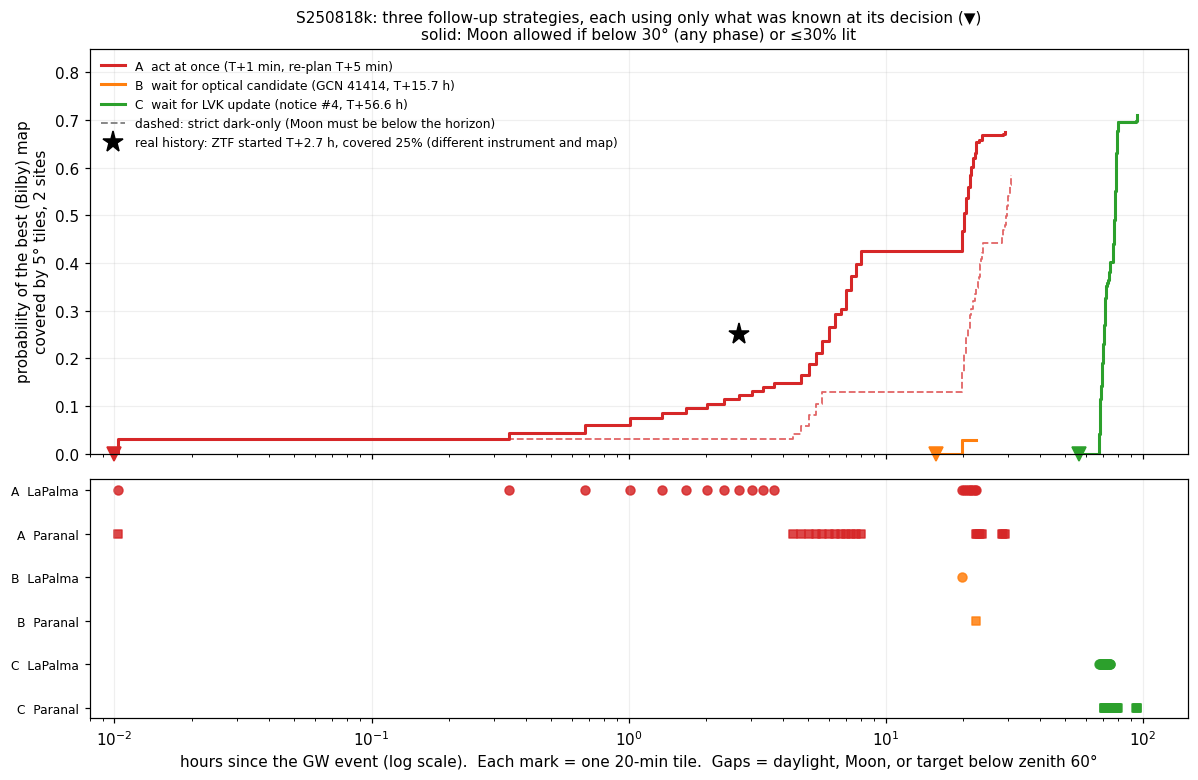

In [9]:
def curves(tiles, truth):
    sc = study.Scorer(study.ROOT / truth, E.BASE.fov_radius)
    out = {}
    for k, df in tiles.items():
        c = sc.cumulative(df); c["hours"] = (c.time - pd.Timestamp(E.T0)).dt.total_seconds() / 3600; out[k] = c
    return out

tiles = {k: res[(E.BASE.tag(), k)] for k in "ABC"}
tiles_d = {k: res[(E.SENSITIVITY["dark time"].tag(), k)] for k in "ABC"}
fig = plots.strategies_figure(tiles, curves(tiles, E.TRUTHS["Hfinal"]), real=E.REAL_ZTF,
                              cur_dark=curves(tiles_d, E.TRUTHS["Hfinal"]))
fig.savefig(FIG / "05_strategies.png", dpi=130); plt.show()

**Reading the result**

* **A** is the only strategy that produces anything on the first night. The first hours are thin because the Moon rises
  (La Palma) and the south lobe is still low (Paranal).
* **B** costs almost no telescope time but covers only the candidate field. Its value depends entirely on the candidate being
  real — AT 2025ulz turned out to be a supernova.
* **C** covers the most, but starts days after the event, when the optical transient was already fading.
* The black star is the **real** history (ZTF started at T+2.7 h and covered 25 %). It is a different instrument
  at a different longitude with no Moon limit, so it is context, not a benchmark.

### What changed with respect to the first version

B and C have a single decision each and give **the very same tiles** in both frameworks (a test checks this). Only A changes, because
its re-plan now knows which field is already being observed:

In [10]:
rows = {}
for moon, name in (("grey", "baseline (2 sites, grey)"), ("dark", "dark time")):
    old = E.first_version_tiles(moon); su = E.SENSITIVITY[name]
    sc = study.Scorer(study.ROOT / E.TRUTHS["Hfinal"], 2.5); sc1 = study.Scorer(study.ROOT / E.TRUTHS["Hearly"], 2.5)
    new = res[(su.tag(), "A")]
    rows[(moon, "first version")] = {"n_tiles": len(old["A"]), "cov_Hfinal": sc.coverage(old["A"]), "cov_planning_map": sc1.coverage(old["A"])}
    rows[(moon, "study.py")] = {"n_tiles": len(new), "cov_Hfinal": sc.coverage(new), "cov_planning_map": sc1.coverage(new)}
pd.DataFrame(rows).T.round(4).rename_axis(["Moon", "strategy A"])

n_tiles  cov_Hfinal  cov_planning_map
Moon strategy A                                          
grey first version     41.0      0.6559            0.7789
     study.py          42.0      0.6752            0.7897
dark first version     35.0      0.5976            0.7060
     study.py          33.0      0.5850            0.6955

* **grey**: A gains one tile at La Palma (the first version dropped a re-planned tile that collided with the running one) and covers
  67.5 % instead of 65.6 % of the Bilby map.
* **dark**: A has 33 instead of 35 tiles and covers 58.5 % instead of 59.8 %. The two missing tiles are fields that the first version
  re-observed without knowing: on top of the new set, each of them would add ≤ 0.3 % of the planning map, below tilepy's 0.5 % per-tile cut,
  so tilepy stops. On its own planning map the new A is as efficient per tile; on the Bilby map the redundant tiles happened to pick up 1.3 %.
* The qualitative picture (A first, C most and last, B narrowest) is unchanged.

### Equal telescope time

Total coverage rewards whoever is allowed more tiles. The fair question is: **after the same number of 20-min tiles, how much is covered?**

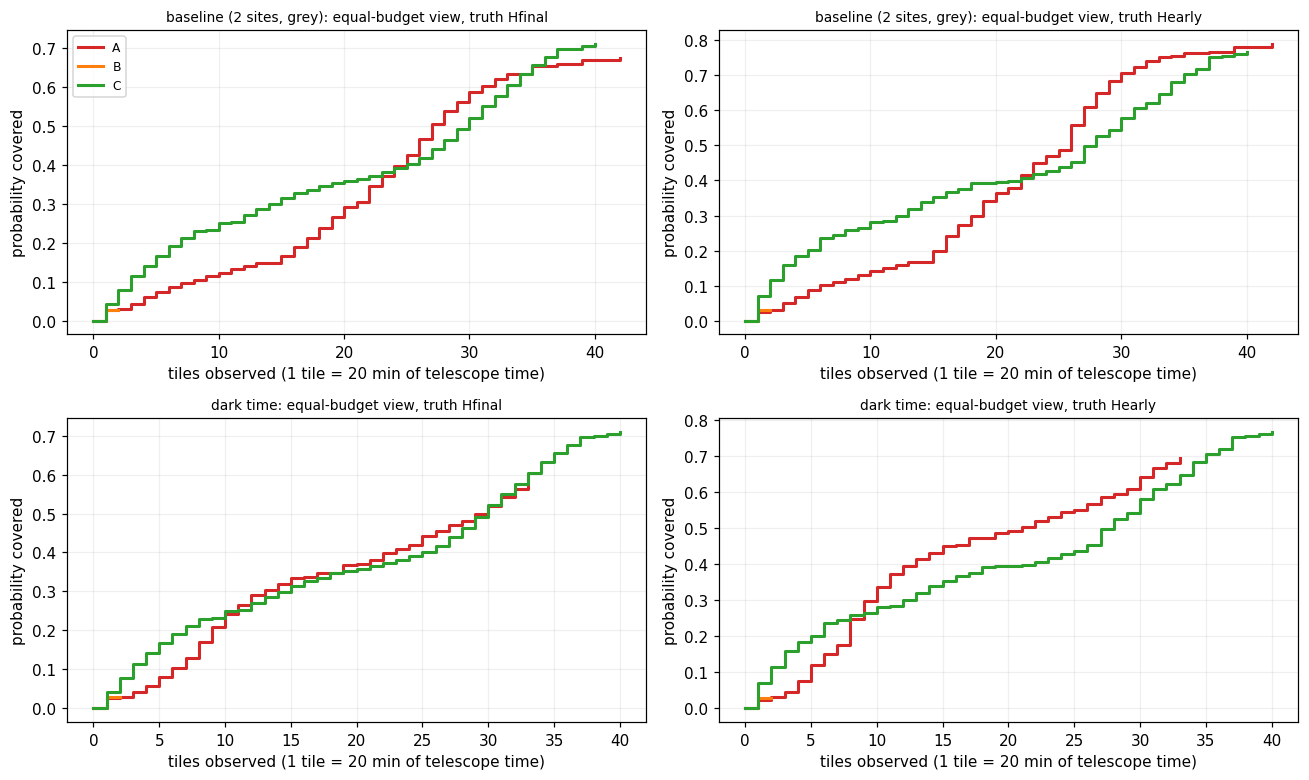

cov_Hfinal_first1  cov_Hfinal_first3  cov_Hfinal_first6  cov_Hfinal_first12  cov_Hearly_first1  cov_Hearly_first3  cov_Hearly_first6  cov_Hearly_first12
setup                    strategy                                                                                                                                                          
baseline (2 sites, grey) A                    0.0269             0.0431             0.0861              0.1400             0.0246             0.0491             0.1031              0.1598
                         B                    0.0279             0.0279             0.0279              0.0279             0.0300             0.0300             0.0300              0.0300
                         C                    0.0422             0.1138             0.1908              0.2698             0.0696             0.1601             0.2371              0.2999
dark time                A                    0.0269             0.0414             0.1047              0.2906             0.0246             0.0452             0.1516              0.3939
                         B                    0.0279             0.0279             0.0279              0.0279             0.0300             0.0300             0.0300              0.0300
                         C                    0.0422             0.1138             0.1908              0.2698             0.0696             0.1601             0.2371              0.2999

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7.2))
for row, name in zip(axes, ("baseline (2 sites, grey)", "dark time")):
    su = E.SENSITIVITY[name]
    ps.coverage_vs_tiles(res, su.tag(), E.STRATEGIES, {k: E.TRUTHS[k] for k in ("Hfinal", "Hearly")}, su, ax_pair=row, nmax=42)
    for ax in row:
        ax.set_title(f"{name}: {ax.get_title()}", fontsize=9)
axes[0, 0].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "06_equal_budget.png", dpi=120); plt.show()
cols = [f"cov_{h}_first{n}" for h in ("Hfinal", "Hearly") for n in (1, 3, 6, 12)]
pd.concat({n: frames[n][cols] for n in ("baseline (2 sites, grey)", "dark time")}, names=["setup", "strategy"])

**Two things need explaining (both checked tile by tile):**

1. *Per tile, C beats A, even when scored on A's own map (Hearly).* A's first tiles are cheap ones: after the first tile, La Palma
   can only observe under the 29 %-lit Moon a part of the map that yields 1–1.7 % per tile, before Paranal's good window opens at T+4.3 h
   (1–2.5 % per tile) and La Palma's second night (2–4 % per tile). C observes on a night with a 6 % Moon.
2. *A covers more per tile in dark time than in grey time* (29 % vs 14 % after 12 tiles). "First n tiles" counts tiles in the order they
   are observed. Grey time *adds* those cheap first-night tiles at the front of the queue; dark time does not allow them, so the 12-tile budget
   reaches the good tiles of the next night. Total coverage is still higher in grey (67.5 % vs 58.5 %).
   **This is a property of the metric, not a paradox**: it measures "if you stop after n tiles", not the best use of n tiles.
   It also says something operational: on this event, the moonlit first-night tiles are the least productive telescope time.

### If AT 2025ulz had been the counterpart (Hcand)

In [12]:
print(summ[["decision_h", "t10_Hcand_h"]].rename(columns={"t10_Hcand_h": "candidate field first observed (h)"}))

          decision_h  candidate field first observed (h)
strategy                                                
A               0.01                               20.52
B              15.69                               19.86
C              56.62                               68.48


A observes the candidate's field at T+20.5 h **without knowing about it**, 40 min after B (T+19.9 h): AT 2025ulz lies at the 34–43 %
credible level of all three LVK maps, where any probability-greedy tiling goes early. On this event the "bet on the candidate" (B) bought
40 minutes, not a night. (The first version of A also covered it at T+20.5 h.)

### Sensitivity

One setting changed at a time with respect to the baseline (2 sites, grey time, FoV radius 2.5°, no reaction delay).

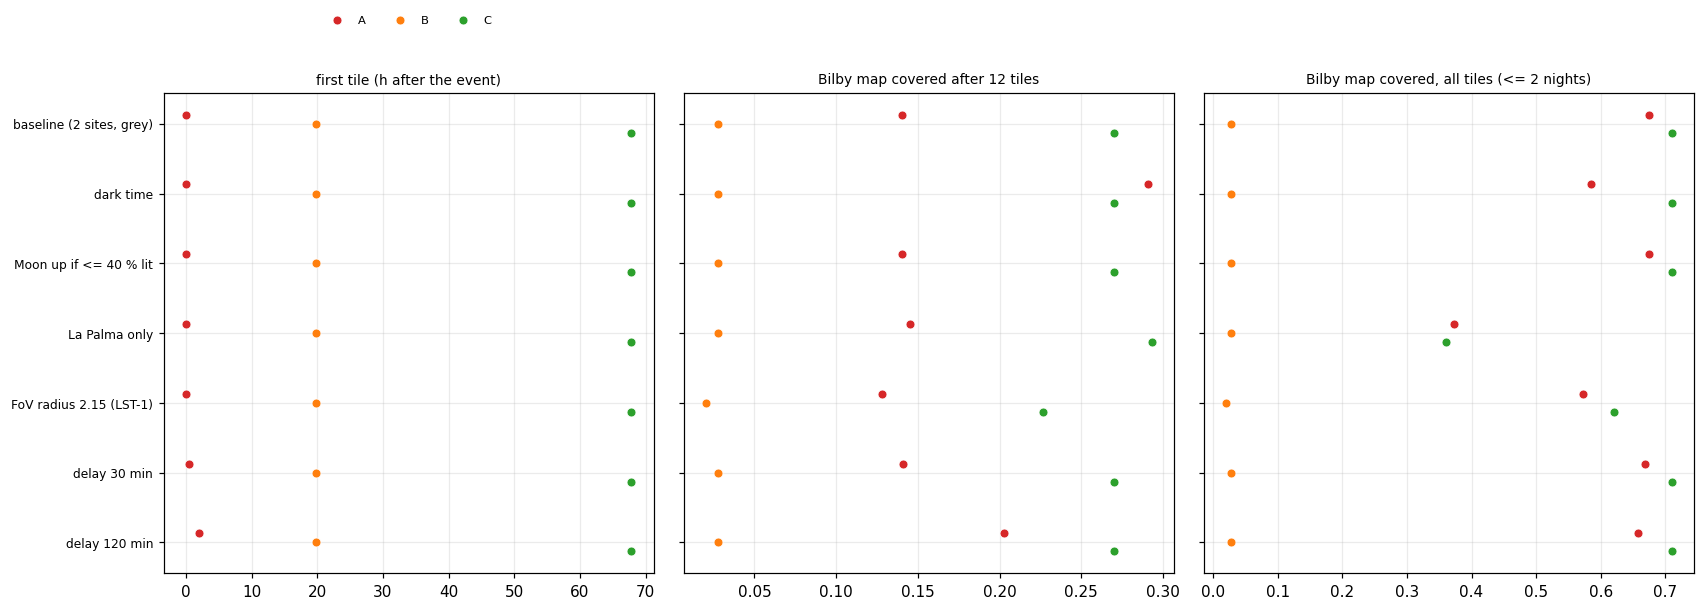

n_tiles        first_tile_h               t10_Hfinal_h            cov_Hfinal_first12               cov_Hfinal             
strategy                       A  B   C            A      B      C            A   B      C                  A      B      C          A      B     C
setup                                                                                                                                              
baseline (2 sites, grey)      42  2  40         0.01  19.86  67.82         2.01 NaN  68.48              0.140  0.028  0.270      0.675  0.028  0.71
dark time                     33  2  40         0.01  19.86  67.82         5.34 NaN  68.48              0.291  0.028  0.270      0.585  0.028  0.71
Moon up if <= 40 % lit        42  2  40         0.01  19.86  67.82         2.01 NaN  68.48              0.140  0.028  0.270      0.675  0.028  0.71
La Palma only                 21  1  20         0.01  19.86  67.82         2.01 NaN  68.48              0.145  0.028  0.293      0.373  0.028  0.36
FoV radius 2.15 (LST-1)       41  2  40         0.01  19.86  67.82         2.68 NaN  68.82              0.128  0.020  0.227      0.573  0.020  0.62
delay 30 min                  40  2  40         0.51  19.86  67.82         2.51 NaN  68.48              0.141  0.028  0.270      0.668  0.028  0.71
delay 120 min                 38  2  40         2.01  19.86  67.82         4.75 NaN  68.48              0.202  0.028  0.270      0.657  0.028  0.71

In [13]:
fig = ps.sensitivity_figure(frames, E.STRATEGIES, metrics=[("first_tile_h", "first tile (h after the event)"),
                                                           ("cov_Hfinal_first12", "Bilby map covered after 12 tiles"),
                                                           ("cov_Hfinal", "Bilby map covered, all tiles (<= 2 nights)")])
fig.savefig(FIG / "07_sensitivity.png", dpi=120); plt.show()
pd.concat({n: f[["n_tiles", "first_tile_h", "t10_Hfinal_h", "cov_Hfinal_first12", "cov_Hfinal"]] for n, f in frames.items()},
          names=["setup", "strategy"]).round(3).unstack("strategy")

* **"Moon up if ≤ 40 % lit" = baseline**: the Moon is 29 % lit on the first night and 6 % on C's night, so both policies allow the same time.
  Only strict dark time changes A (time to 10 %: 2.0 h → 5.3 h).
* **Reaction delay** (30 / 120 min) costs A 0.5 / 2.7 h in time to 10 % but almost nothing in total coverage (67.5 → 66.8 / 65.7 %).
* **La Palma only**: A and C cover about the same (37.3 % vs 36.0 %): the C advantage comes from Paranal's second night.
* **FoV radius 2.15° (LST-1)**: A and C lose 13–15 % of their coverage (relative), B 27 %; the ranking does not change.

## 6. Quiz mode (observer training)

`Quiz.ask` shows the leak-free snapshot at *T* and the decision questions; `Quiz.reveal` then shows what actually arrived next.

In [14]:
q = Quiz(log)
q.ask(hours=0.1)

=== S250818k @ 2025-08-18T01:26:06  (T0 + 0.10 h) ===
Latest LVK alert: Preliminary #2 (available 2025-08-18T01:25:20)
  localisation: 50%=205 deg2  90%=786 deg2  lobes(90%): (72,-48), (253,+48)
  peak-probability pixel (not the localisation!): RA=242.4 Dec=+37.2
  distance ~259 Mpc  FAR=2.15 per year
  class: Terrestrial=71% BNS=29% NSBH=0% BBH=0%;  P(has NS | astrophysical)=1.0
  comment: (none)
Alerts so far: 2 -> Preliminary #1, Preliminary #2
GCN circulars so far: 0  {}

--- Your turn ---
1. Which observatories could start tonight, and on which part of the sky?
2. Do you tile the whole localisation now, or wait for more information? What would change your mind?
3. How many hours of telescope time are you willing to spend on a 71% chance that this is noise?


In [15]:
q.reveal(hours=0.1, window_hours=12)   # run this only after you have decided

=== Reveal: what arrived in the next 12 h (T0 + 0.10 h -> +12 h) ===
  T0+   8.31 h  MAXI/GSC     GCN 41410    LIGO/Virgo/KAGRA S250818k: Coverage and upper limits from MAXI/GSC observation


In [16]:
q.ask(hours=57)
q.reveal(hours=57, window_hours=24)

=== S250818k @ 2025-08-20T10:20:06  (T0 + 57.00 h) ===
Latest LVK alert: Update #4 (available 2025-08-20T09:57:17)
  localisation: 50%=275 deg2  90%=949 deg2  lobes(90%): (72,-47), (251,+47)
  peak-probability pixel (not the localisation!): RA=242.8 Dec=+37.5
  distance ~237 Mpc  FAR=2.15 per year
  class: Terrestrial=71% BNS=29% NSBH=0% BBH=0%;  P(has NS | astrophysical)=0.8
  comment: sub-threshold trigger coincident with ZTF25abjmnps / AT 2025ulz
Alerts so far: 5 -> Preliminary #1, Preliminary #2, Initial #3, Initial #3, Update #4
GCN circulars so far: 8  {'xray_followup': 1, 'optical_followup': 4, 'spectroscopy': 1, 'general_report': 2}
  2025-08-20T01:24:58  GCN 41433  FTW              LIGO/Virgo/KAGRA S250818k: FTW Fast reddening of AT 2025ulz
  2025-08-20T05:23:53  GCN 41436  Keck             LIGO/Virgo/KAGRA S250818k: Keck I LRIS spectroscopy of ZTF25abjmnps (A
  2025-08-20T06:04:03  GCN 41437  LVK              LIGO/Virgo/KAGRA S250818k: Properties of the low-significance GW co

## Known limitations (please read)

**Data and timing**
* The log contains only what Astro-COLIBRI recorded for this event plus the text of GCN circulars. Other real-time channels
  (other missions' notices, mailing lists, private channels) are **not** included, so "what was known" is a lower bound.
* LVK knowledge time = `last_modified` of the first 5 archive revisions (`S250818k_0…_4`); later revisions are platform
  re-archiving and are ignored. GCN knowledge time = NASA's `createdOn` rounded up to the next second (the circular's `DATE:` header agrees to < 1 s but can be up to 1 s early, so it is only a fallback).
* **Old events are not replayable this way**: for GRB 221009A all 250 archive revisions carry 2026 back-fill timestamps.
* Sky maps come from public GraceDB, matched to alerts by the GraceDB log timestamps (`bayestar,2` is a copy of `,1`).

**Strategy comparison**
* Idealised: **zero reaction/slew delay**, a generic circular field of view of 5° diameter (not a real instrument), 20-min
  tiles, no weather, two sites only (a 30/120-min delay and a 2.15° radius are tested in the sensitivity section).
* Coverage is the probability of the *Bilby* map inside the tiles. It is **not** a detection probability: this alert was
  71 % terrestrial and the optical counterpart candidate was a supernova.
* tilepy's `fov` option is a circle **radius** (an early version of this analysis wrongly assumed a diameter; it is now fixed and a
  regression test compares our scoring with tilepy's own planned probability).
* tilepy checks its constraints at the **start** of each run. At run end the zenith angle can exceed 60° by a few degrees and
  the Moon altitude by about 1°.
* **Moon policy semantics were inferred from tilepy's source and experiments**, not from its documentation. Setting `moongrey = 90`
  silently disables the whole Moon constraint. For this event the results are nearly identical for any illumination limit between
  20 % and 35 % (time to 10 % coverage: 2.1 h in all cases); what matters is whether observing with the Moon up is allowed at all
  (strict "Moon below horizon": 5.4 h). tilepy's grey time is an OR: Moon below 30° at any illumination, or higher if under the illumination limit; the 30° is our own choice, and tilepy's definition of lunar phase was not verified.
* The visibility figure (section 4) ignores the Moon.
* Strategy A re-plans at T+5 min; the tile still running is kept and passed to tilepy as already observed (the first version of
  this analysis did not pass it; numbers of both versions are given in section 5).
* Equal-budget metrics count tiles in time order ("if you stop after n tiles"), not the best use of n tiles.
* With two sites, each site is planned independently: fields can be observed from both (the totals are a lower bound for a coordinated plan).
* **Hcand** is a hypothesis for scoring only; AT 2025ulz was later found to be a supernova.
* One event only; generality across event types is untested.

**Labels**
* The observation categories of the GCN circulars (optical / X-ray / radio …) are produced **automatically by an LLM on the platform**,
  months after the fact, and are not fully consistent (e.g. `spectroscopic` vs `spectroscopy`). They are used only for colouring plots.